# Wprowadzenie do uczenia maszynowego - Lista 1
Konrad Słotta 277442

In [149]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

## Zadanie 2

In [150]:
from sklearn.datasets import load_iris

In [151]:
df = load_iris(as_frame=True)
iris = df.data

iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [152]:
iris.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## Zadanie 3

In [153]:
import kagglehub

path = kagglehub.dataset_download("yasserh/titanic-dataset")

file_path = os.path.join(path, "Titanic-Dataset.csv")

titanic_1 = pd.read_csv(file_path)

titanic_1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [154]:
titanic_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [181]:
titanic_1["Cabin"] = titanic_1["Cabin"].fillna("Unknown")
titanic_1 = titanic_1.dropna(subset=['Embarked'])
titanic_1["Age"] = titanic_1["Age"].fillna(titanic_1["Age"].median())
print(titanic_1["Age"].median())
pd.set_option("display.max_rows", None)
#titanic_1

28.0


In [156]:
titanic_1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    object 
 5   Age          889 non-null    float64
 6   SibSp        889 non-null    int64  
 7   Parch        889 non-null    int64  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float64
 10  Cabin        889 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 90.3+ KB


## Zadanie 4

In [157]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
cat_cols = ['Sex', 'Embarked']

titanic_1_encoded_pd = pd.get_dummies(titanic_1, columns=cat_cols)
titanic_1_encoded_pd = titanic_1_encoded_pd.drop(columns=['Sex_female'])

titanic_1_encoded_pd.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,Unknown,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,Unknown,False,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,False,False,False,True
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,Unknown,True,False,False,True


In [159]:
encoder = OneHotEncoder(sparse_output=False)

encoded_array = encoder.fit_transform(titanic_1[cat_cols])

encoded_col_names = encoder.get_feature_names_out(cat_cols)

titanic_encoded_sk = pd.DataFrame(encoded_array, columns=encoded_col_names, index=titanic_1.index)

titanic_1_encoded_sk = pd.concat(
    [titanic_1.drop(columns=cat_cols), titanic_encoded_sk], 
    axis=1
)

titanic_1_encoded_sk = titanic_1_encoded_sk.drop(columns=['Sex_female'])
titanic_1_encoded_sk.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,Unknown,1.0,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0.0,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,Unknown,0.0,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0.0,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,Unknown,1.0,0.0,0.0,1.0


## Zadanie 5

In [160]:
def standard_scaler(df):
    mean = df.mean(axis=0)
    std = df.std(axis=0, ddof=0)
    return (df - mean) / std

def min_max_scaler(df, feature_range=(0, 1)):
    min_val = df.min(axis=0)
    max_val = df.max(axis=0)
    
    scaled = (df - min_val) / (max_val - min_val)

    a, b = feature_range
    return scaled * (b - a) + a


In [161]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Text(0.5, 1.0, 'Original data')

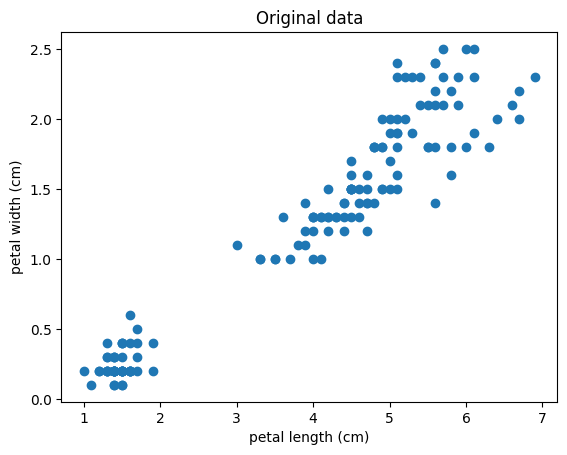

In [162]:
petal = ['petal length (cm)', 'petal width (cm)']
iris_petals = iris[petal]
plt.scatter(iris_petals[petal[0]], iris_petals[petal[1]])
plt.xlabel(petal[0])
plt.ylabel(petal[1])
plt.title('Original data')

Text(0.5, 1.0, 'Standarized data')

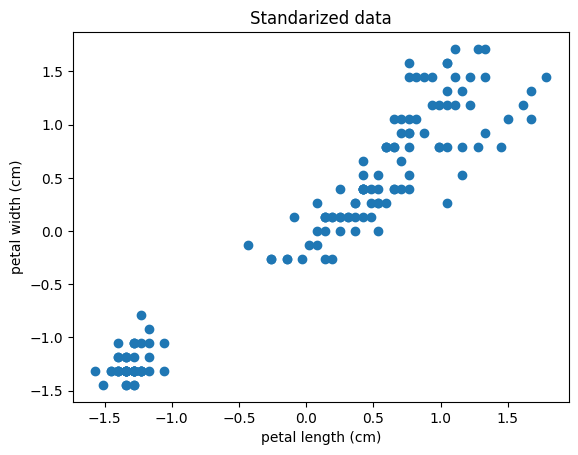

In [163]:
iris_custom_st = standard_scaler(iris_petals)
plt.scatter(iris_custom_st[petal[0]], iris_custom_st[petal[1]])
plt.xlabel(petal[0])
plt.ylabel(petal[1])
plt.title('Standarized data')

Text(0.5, 1.0, 'Standarized data')

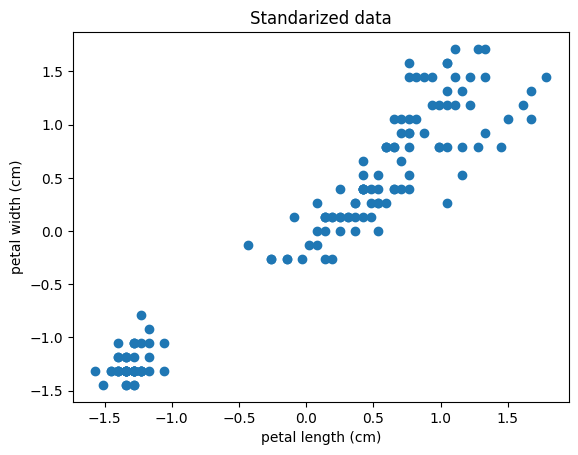

In [164]:
scaler_st = StandardScaler()
iris_petals_st = scaler_st.fit_transform(iris_petals)

plt.scatter(iris_petals_st[:, 0], iris_petals_st[:, 1])
plt.xlabel(petal[0])
plt.ylabel(petal[1])
plt.title('Standarized data')

Text(0.5, 1.0, 'Normalized data')

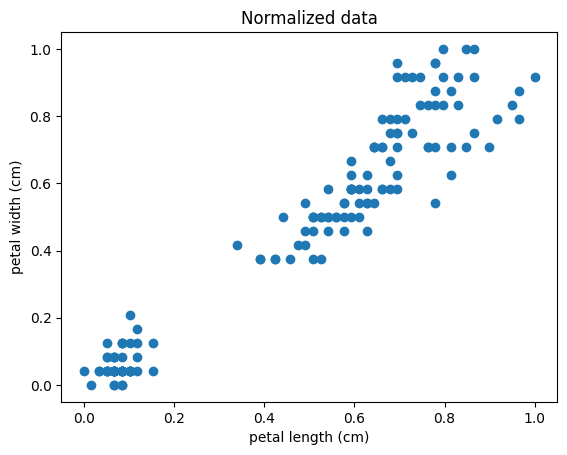

In [165]:
iris_custom_mm = min_max_scaler(iris_petals)
plt.scatter(iris_custom_mm[petal[0]], iris_custom_mm[petal[1]])
plt.xlabel(petal[0])
plt.ylabel(petal[1])
plt.title('Normalized data')

Text(0.5, 1.0, 'Normalized data')

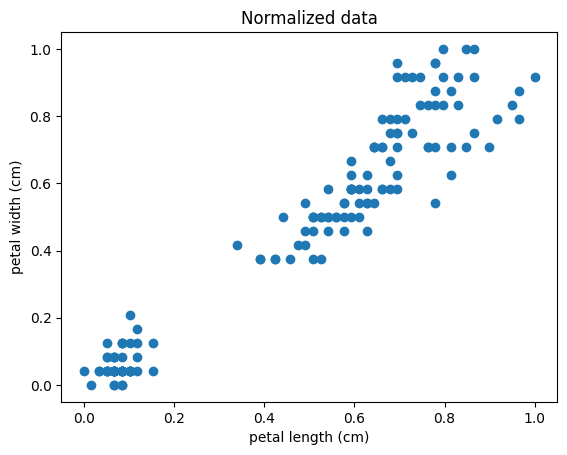

In [166]:
scaler_mm = MinMaxScaler()
iris_petals_mm = scaler_mm.fit_transform(iris_petals)

plt.scatter(iris_petals_mm[:, 0], iris_petals_mm[:, 1])
plt.xlabel(petal[0])
plt.ylabel(petal[1])
plt.title('Normalized data')

## Zadanie 6

In [167]:
from sklearn.model_selection import train_test_split
y = df.target
print("X ", "y")
print(iris.size, y.size)
X_train, X_test, y_train, y_test = train_test_split(iris, y, test_size=0.3)
print("X_train ", "X_test ", "y_train ", "y_test ")
print(X_train.size, X_test.size, y_train.size, y_test.size)

X  y
600 150
X_train  X_test  y_train  y_test 
420 180 105 45


In [168]:
X_train.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
141,6.9,3.1,5.1,2.3
102,7.1,3.0,5.9,2.1
148,6.2,3.4,5.4,2.3
32,5.2,4.1,1.5,0.1
86,6.7,3.1,4.7,1.5


In [169]:
X_test.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
66,5.6,3.0,4.5,1.5
73,6.1,2.8,4.7,1.2
42,4.4,3.2,1.3,0.2
5,5.4,3.9,1.7,0.4
2,4.7,3.2,1.3,0.2


## Zadanie 7

In [170]:
path = kagglehub.dataset_download("claudiodavi/superhero-set")

sup_file_path = os.path.join(path, "heroes_information.csv")

sup_df = pd.read_csv(sup_file_path)
sup_df.head()

,Unnamed: 0,name,Gender,Eye color,Race,Hair color,Height,Publisher,Skin color,Alignment,Weight
0,0,A-Bomb,Male,yellow,Human,No Hair,203.0,Marvel Comics,-,good,441.0
1,1,Abe Sapien,Male,blue,Icthyo Sapien,No Hair,191.0,Dark Horse Comics,blue,good,65.0
2,2,Abin Sur,Male,blue,Ungaran,No Hair,185.0,DC Comics,red,good,90.0
3,3,Abomination,Male,green,Human / Radiation,No Hair,203.0,Marvel Comics,-,bad,441.0
4,4,Abraxas,Male,blue,Cosmic Entity,Black,-99.0,Marvel Comics,-,bad,-99.0


In [171]:
sup_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  734 non-null    int64  
 1   name        734 non-null    object 
 2   Gender      734 non-null    object 
 3   Eye color   734 non-null    object 
 4   Race        734 non-null    object 
 5   Hair color  734 non-null    object 
 6   Height      734 non-null    float64
 7   Publisher   719 non-null    object 
 8   Skin color  734 non-null    object 
 9   Alignment   734 non-null    object 
 10  Weight      732 non-null    float64
dtypes: float64(2), int64(1), object(8)
memory usage: 63.2+ KB


In [172]:
#sup_df

In [173]:

count = (sup_df['Weight'] == -99).sum()
print(count)

237


In [174]:
sup_df_clean = sup_df[(sup_df['Height'] >= 0) & (sup_df['Weight'] >= 0)].copy()
sup_df_clean['Publisher'] = sup_df_clean['Publisher'].fillna('Unknown')
sup_df_clean = sup_df_clean.dropna(subset=['Weight'])
sup_df_clean.rename(columns={'Unnamed: 0': 'id'}, inplace=True)
sup_df_clean.replace({
    'Gender': {'-': 'other/unknown'},
    'Alignment': {'-': 'unknown'}
}, inplace=True)
sup_df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 490 entries, 0 to 733
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          490 non-null    int64  
 1   name        490 non-null    object 
 2   Gender      490 non-null    object 
 3   Eye color   490 non-null    object 
 4   Race        490 non-null    object 
 5   Hair color  490 non-null    object 
 6   Height      490 non-null    float64
 7   Publisher   490 non-null    object 
 8   Skin color  490 non-null    object 
 9   Alignment   490 non-null    object 
 10  Weight      490 non-null    float64
dtypes: float64(2), int64(1), object(8)
memory usage: 45.9+ KB


In [175]:
sp_cat_cols = ['Gender', 'Alignment']

sup_df_cat = pd.get_dummies(sup_df_clean, columns = sp_cat_cols)

sup_df_cat.head()

,id,name,Eye color,Race,Hair color,Height,Publisher,Skin color,Weight,Gender_Female,Gender_Male,Gender_other/unknown,Alignment_bad,Alignment_good,Alignment_neutral,Alignment_unknown
0,0,A-Bomb,yellow,Human,No Hair,203.0,Marvel Comics,-,441.0,False,True,False,False,True,False,False
1,1,Abe Sapien,blue,Icthyo Sapien,No Hair,191.0,Dark Horse Comics,blue,65.0,False,True,False,False,True,False,False
2,2,Abin Sur,blue,Ungaran,No Hair,185.0,DC Comics,red,90.0,False,True,False,False,True,False,False
3,3,Abomination,green,Human / Radiation,No Hair,203.0,Marvel Comics,-,441.0,False,True,False,True,False,False,False
5,5,Absorbing Man,blue,Human,No Hair,193.0,Marvel Comics,-,122.0,False,True,False,True,False,False,False


In [176]:
from sklearn.preprocessing import RobustScaler
rb_scaler = RobustScaler()

sup_num_cols = ['Height', 'Weight']
sup_rb_cols = ['Height_rb', 'Weight_rb']
sup_df_cat[sup_rb_cols] = rb_scaler.fit_transform(sup_df_cat[sup_num_cols])

sup_df_cat.head()

,id,name,Eye color,Race,Hair color,Height,Publisher,Skin color,Weight,Gender_Female,Gender_Male,Gender_other/unknown,Alignment_bad,Alignment_good,Alignment_neutral,Alignment_unknown,Height_rb,Weight_rb
0,0,A-Bomb,yellow,Human,No Hair,203.0,Marvel Comics,-,441.0,False,True,False,False,True,False,False,1.379310,8.000000
1,1,Abe Sapien,blue,Icthyo Sapien,No Hair,191.0,Dark Horse Comics,blue,65.0,False,True,False,False,True,False,False,0.551724,-0.355556
2,2,Abin Sur,blue,Ungaran,No Hair,185.0,DC Comics,red,90.0,False,True,False,False,True,False,False,0.137931,0.200000
3,3,Abomination,green,Human / Radiation,No Hair,203.0,Marvel Comics,-,441.0,False,True,False,True,False,False,False,1.379310,8.000000
5,5,Absorbing Man,blue,Human,No Hair,193.0,Marvel Comics,-,122.0,False,True,False,True,False,False,False,0.689655,0.911111


Text(0.5, 1.0, 'Raw data')

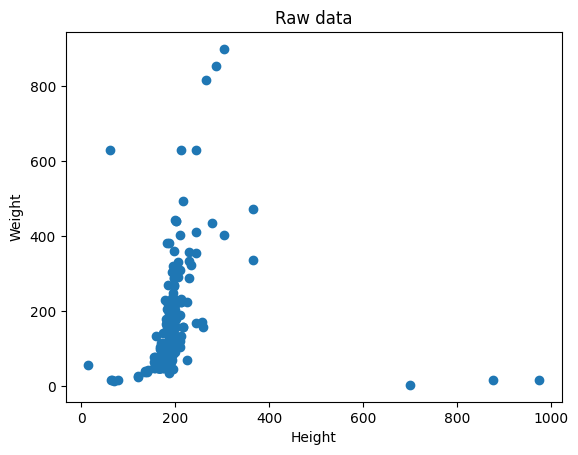

In [177]:
plt.scatter(sup_df_cat[sup_num_cols[0]], sup_df_cat[sup_num_cols[1]])
plt.xlabel(sup_num_cols[0])
plt.ylabel(sup_num_cols[1])
plt.title('Raw data')

Text(0.5, 1.0, 'Robusted data')

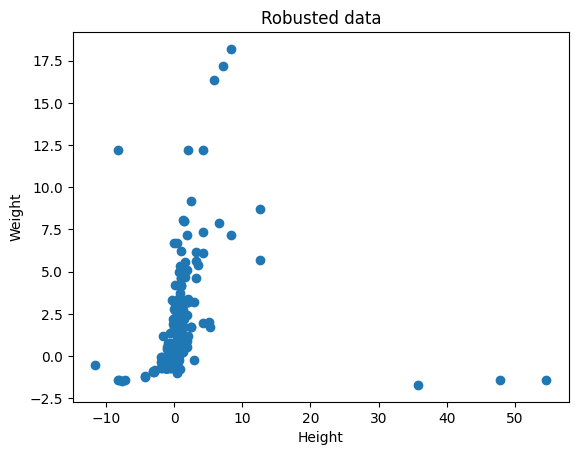

In [178]:
plt.scatter(sup_df_cat[sup_rb_cols[0]], sup_df_cat[sup_rb_cols[1]])
plt.xlabel(sup_num_cols[0])
plt.ylabel(sup_num_cols[1])
plt.title('Robusted data')

In [179]:
sup_df_cat.to_csv('superheroes_data_ready.csv', index=False)